# Step 2: Demand Patterns And Exploratory Analysis

This notebook focuses on when customers place orders.

It builds the descriptive layer for the project by analyzing:
- hourly demand
- weekday demand
- a weekday-by-hour demand heatmap
- the busiest and slowest operating windows


In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)


In [2]:
from pathlib import Path


def find_project_root() -> Path:
    current = Path.cwd().resolve()
    for candidate in (current, current.parent):
        if (candidate / "orders.csv").exists() and (candidate / "products.csv").exists():
            return candidate
    raise FileNotFoundError("Could not locate the project root that contains the Instacart CSV files.")


PROJECT_ROOT = find_project_root()
OUTPUT_DIR = PROJECT_ROOT / "outputs"
ANALYSIS_DIR = OUTPUT_DIR / "analysis"
FIGURE_DIR = OUTPUT_DIR / "figures"
QUALITY_DIR = OUTPUT_DIR / "quality"

for path in (OUTPUT_DIR, ANALYSIS_DIR, FIGURE_DIR, QUALITY_DIR):
    path.mkdir(parents=True, exist_ok=True)


In [3]:
orders = pd.read_csv(PROJECT_ROOT / "orders.csv", parse_dates=["timestamp"])

orders["order_hour"] = orders["timestamp"].dt.hour
orders["order_day_name"] = orders["timestamp"].dt.day_name()
orders["order_day_of_week"] = orders["timestamp"].dt.dayofweek
orders["order_date"] = orders["timestamp"].dt.date

weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]


In [4]:
hourly_profile = (
    orders.groupby("order_hour")
    .size()
    .rename("order_count")
    .reset_index()
)

weekday_profile = (
    orders.groupby(["order_day_of_week", "order_day_name"])
    .size()
    .rename("order_count")
    .reset_index()
    .sort_values("order_day_of_week")
)

heatmap_profile = (
    orders.groupby(["order_day_name", "order_hour"])
    .size()
    .rename("order_count")
    .reset_index()
)

heatmap_table = (
    heatmap_profile.pivot(index="order_day_name", columns="order_hour", values="order_count")
    .reindex(weekday_order)
)

hourly_profile.head()


,order_hour,order_count
0,0,22224
1,1,12103
2,2,7375
3,3,5343
4,4,5393


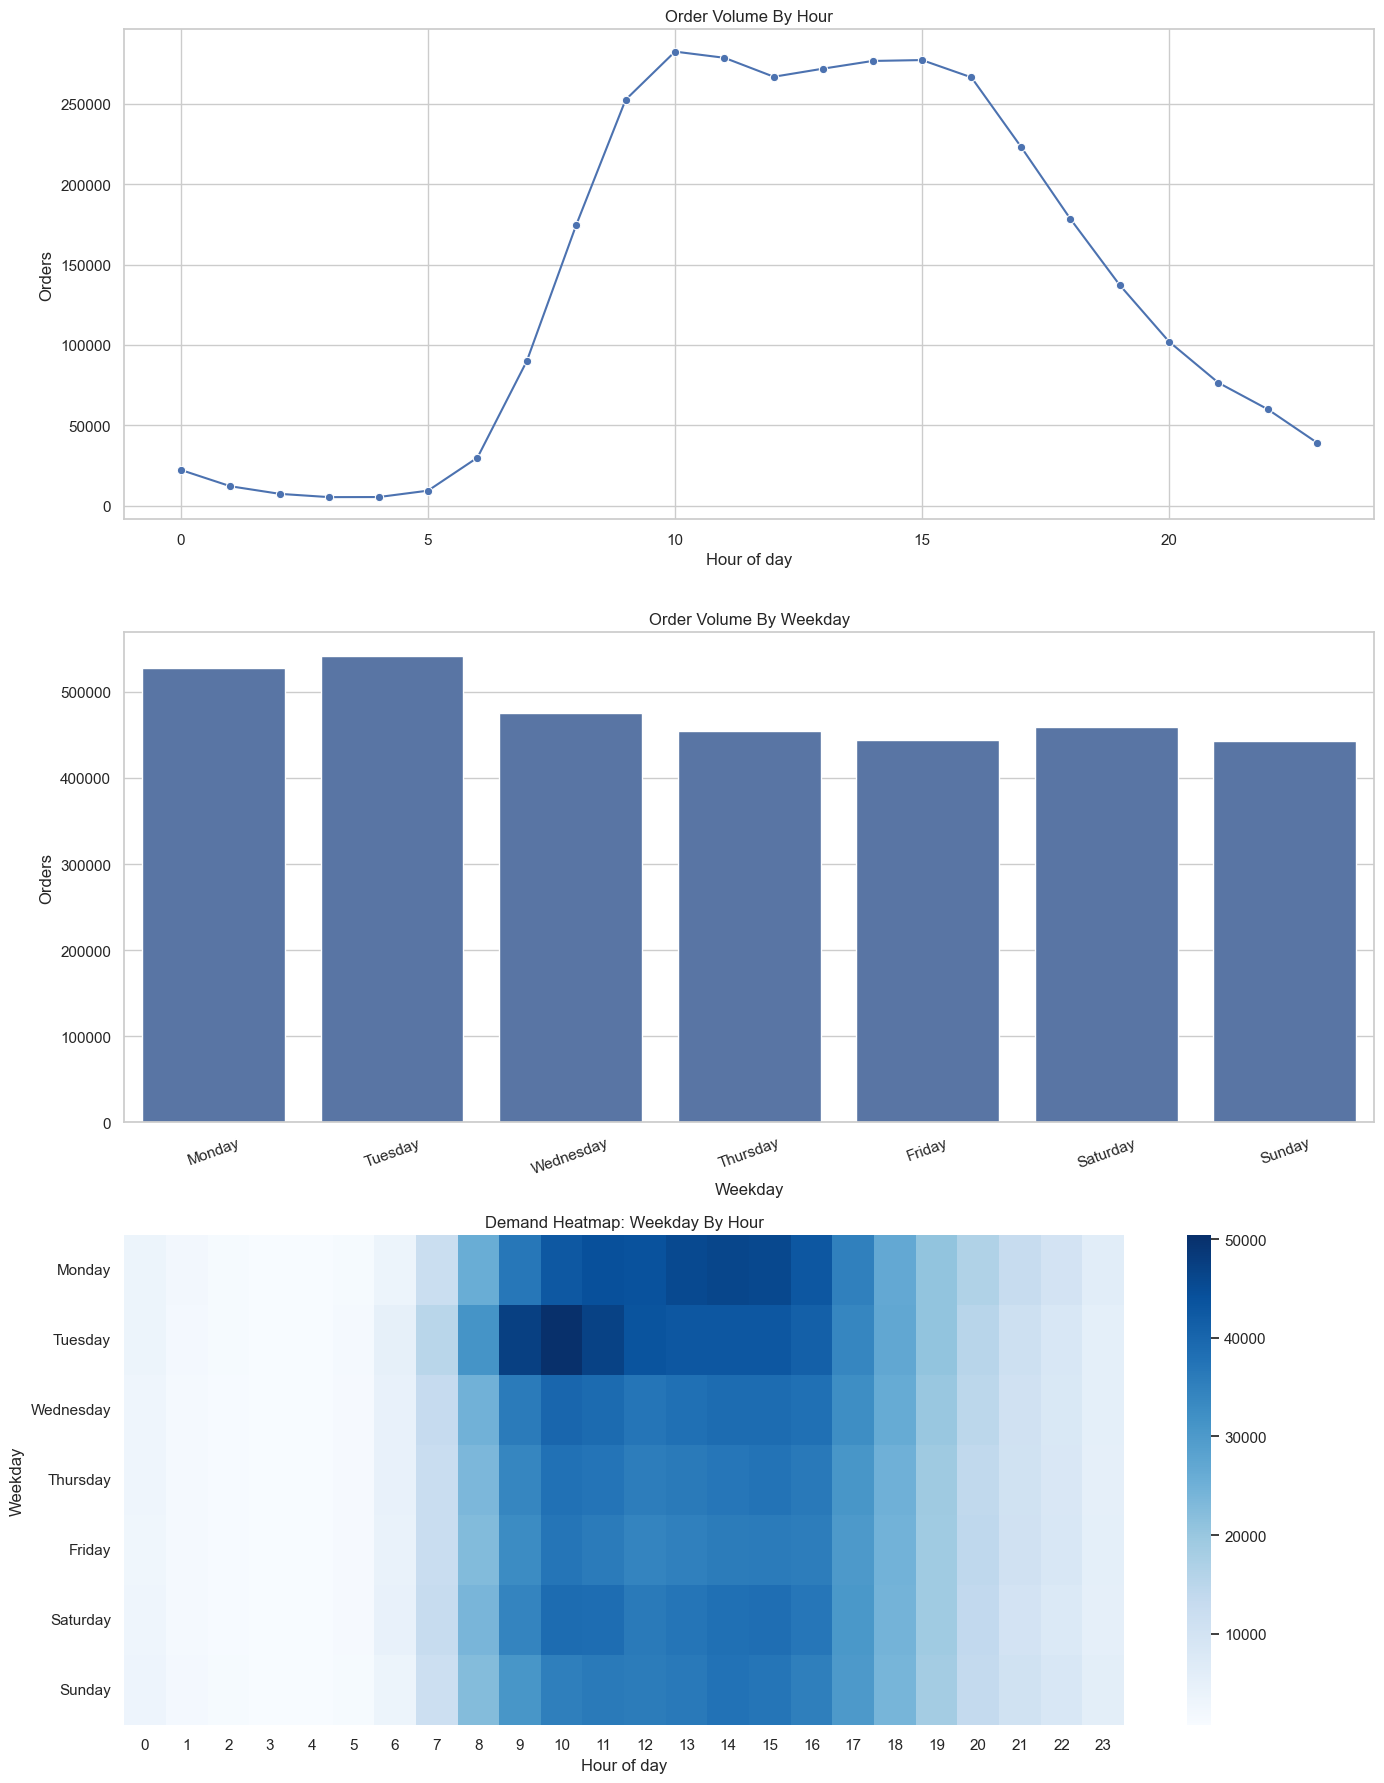

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(14, 18))

sns.lineplot(data=hourly_profile, x="order_hour", y="order_count", marker="o", ax=axes[0])
axes[0].set_title("Order Volume By Hour")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Orders")

sns.barplot(data=weekday_profile, x="order_day_name", y="order_count", order=weekday_order, ax=axes[1])
axes[1].set_title("Order Volume By Weekday")
axes[1].set_xlabel("Weekday")
axes[1].set_ylabel("Orders")
axes[1].tick_params(axis="x", rotation=20)

sns.heatmap(heatmap_table, cmap="Blues", ax=axes[2])
axes[2].set_title("Demand Heatmap: Weekday By Hour")
axes[2].set_xlabel("Hour of day")
axes[2].set_ylabel("Weekday")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "demand_patterns.png", dpi=150, bbox_inches="tight")
plt.show()


In [6]:
busiest_hour = hourly_profile.loc[hourly_profile["order_count"].idxmax()]
slowest_hour = hourly_profile.loc[hourly_profile["order_count"].idxmin()]
busiest_day = weekday_profile.loc[weekday_profile["order_count"].idxmax()]
slowest_day = weekday_profile.loc[weekday_profile["order_count"].idxmin()]

summary = pd.DataFrame(
    [
        {"metric": "busiest_hour", "value": int(busiest_hour["order_hour"]), "order_count": int(busiest_hour["order_count"])},
        {"metric": "slowest_hour", "value": int(slowest_hour["order_hour"]), "order_count": int(slowest_hour["order_count"])},
        {"metric": "busiest_day", "value": busiest_day["order_day_name"], "order_count": int(busiest_day["order_count"])},
        {"metric": "slowest_day", "value": slowest_day["order_day_name"], "order_count": int(slowest_day["order_count"])},
    ]
)

hourly_profile.to_csv(ANALYSIS_DIR / "hourly_profile.csv", index=False)
weekday_profile.to_csv(ANALYSIS_DIR / "weekday_profile.csv", index=False)
heatmap_profile.to_csv(ANALYSIS_DIR / "weekday_hour_profile.csv", index=False)
summary.to_csv(ANALYSIS_DIR / "demand_summary.csv", index=False)

summary


,metric,value,order_count
0,busiest_hour,10,282470
1,slowest_hour,3,5343
2,busiest_day,Tuesday,542103
3,slowest_day,Sunday,442564


## Step 2 Outcome

After running this notebook you will have:
- visual evidence of peak and low-demand periods
- CSV summaries saved into `outputs/analysis/`
- a figure exported to `outputs/figures/demand_patterns.png`
